In [ ]:
!nvidia-smi

Mon Oct 26 20:59:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   45C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 14.56


In [ ]:
from pathlib import Path

PROJECT_DIR = Path("/content/FrameRevive")

DATA_DIR = PROJECT_DIR / "data"
RESULT_DIR = PROJECT_DIR / "result"
MODEL_DIR = PROJECT_DIR / "model"

for directory in [PROJECT_DIR, DATA_DIR, RESULT_DIR, MODEL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)
print("Project directory: ", PROJECT_DIR)

Project directory:  /content/FrameRevive


In [ ]:
import requests

url = "https://data.vision.ee.ethz.ch/csergi/share/davis/DAVIS-2017-trainval-480p.zip"

zip_path = DATA_DIR / "davis_trainval.zip"

with requests.get(url, stream=True, timeout=120) as response:
    response.raise_for_status()

    with open(zip_path, "wb") as f:
        for chunk in response.iter_content(chunk_size=1024 * 1024):
            if chunk:
                f.write(chunk)

print("Download successful!")
print("Size (MB):", round(zip_path.stat().st_size / 1024**2, 2))

Download successful!
Size (MB): 794.19


In [ ]:
import zipfile

with zipfile.ZipFile(zip_path, "r") as zip_ref:
  zip_ref.extractall(DATA_DIR)
print("dataset extract successfully!")

dataset extract successfully!


Total frames: 50
Frame shape: (480, 854, 3)
Data type: uint8


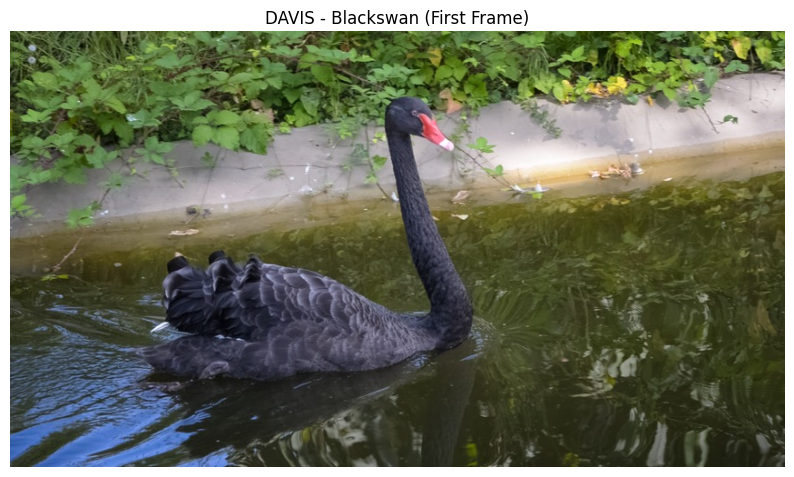

In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

frames_dir = DATA_DIR / "DAVIS" / "JPEGImages" / "480p" / "blackswan"

frame_paths = sorted(frames_dir.glob("*.jpg"))

print("Total frames:", len(frame_paths))

if not frame_paths:
    raise FileNotFoundError(f"No frames found in {frames_dir}")

first_frame = np.array(Image.open(frame_paths[0]).convert("RGB"))

print("Frame shape:", first_frame.shape)
print("Data type:", first_frame.dtype)

plt.figure(figsize=(10, 6))
plt.imshow(first_frame)
plt.title("DAVIS - Blackswan (First Frame)")
plt.axis("off")
plt.show()

In [ ]:
frames = []

for path in frame_paths[:10]:
    frame = np.array(Image.open(path).convert("RGB"))
    frames.append(frame)

frames = np.stack(frames)

print("Video shape:", frames.shape)

Video shape: (10, 480, 854, 3)


In [ ]:
clean_frames = frames.astype(np.float32) / 255.0

rng = np.random.default_rng(42)

noise = rng.normal(
    loc = 0,
    scale = 0.2,
    size = clean_frames.shape
)
noisy_frames = np.clip(clean_frames + noise, 0, 1).astype(np.float32)


print("Clean frames shape:", clean_frames.shape)
print("Noisy frames shape:", noisy_frames.shape)

Clean frames shape: (10, 480, 854, 3)
Noisy frames shape: (10, 480, 854, 3)


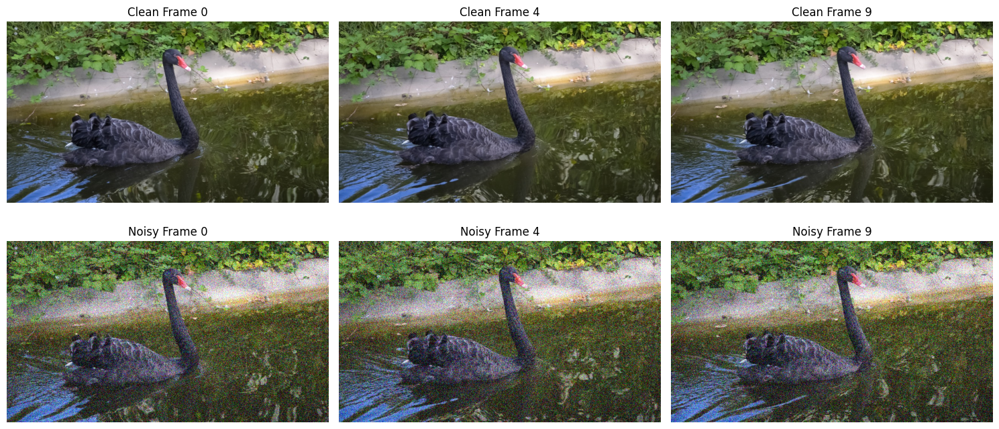

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

frame_indices = [0, 4, 9]

for i, idx in enumerate(frame_indices):
    axes[0, i].imshow(clean_frames[idx])
    axes[0, i].set_title(f"Clean Frame {idx}")
    axes[0, i].axis("off")

    axes[1, i].imshow(noisy_frames[idx])
    axes[1, i].set_title(f"Noisy Frame {idx}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

psnr_scores = []
ssim_scores = []

for i in range(len(clean_frames)):
    psnr = peak_signal_noise_ratio(
        clean_frames[i],
        noisy_frames[i],
        data_range=1.0
    )

    ssim = structural_similarity(
        clean_frames[i],
        noisy_frames[i],
        channel_axis=-1,
        data_range=1.0
    )

    psnr_scores.append(psnr)
    ssim_scores.append(ssim)

print("Average PSNR:", round(np.mean(psnr_scores), 2), "dB")
print("Average SSIM:", round(np.mean(ssim_scores), 4))

Average PSNR: 14.84 dB
Average SSIM: 0.1587


In [ ]:
from skimage.filters import gaussian

gaussian_frames = []

for frame in noisy_frames:
  denoised = gaussian(
      frame,
      sigma = 1.0,
      channel_axis = 1
  )
  gaussian_frames.append(denoised)

gaussian_frames = np.stack(gaussian_frames)

print("Gaussian frames shape:", gaussian_frames.shape)

Gaussian frames shape: (10, 480, 854, 3)


In [ ]:
gaussian_psnr = []
gaussian_ssim = []

for i in range(len(clean_frames)):

    psnr = peak_signal_noise_ratio(
        clean_frames[i],
        gaussian_frames[i],
        data_range=1.0
    )

    ssim = structural_similarity(
        clean_frames[i],
        gaussian_frames[i],
        channel_axis=-1,
        data_range=1.0
    )

    gaussian_psnr.append(psnr)
    gaussian_ssim.append(ssim)

print("Gaussian PSNR:", round(np.mean(gaussian_psnr), 2), "dB")
print("Gaussian SSIM:", round(np.mean(gaussian_ssim), 4))

Gaussian PSNR: 21.54 dB
Gaussian SSIM: 0.4356


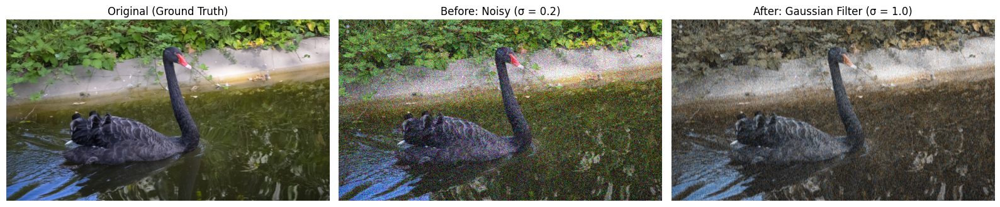

In [ ]:
frame_idx = 0

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

images = [
    clean_frames[frame_idx],
    noisy_frames[frame_idx],
    gaussian_frames[frame_idx]
]

titles = [
    "Original (Ground Truth)",
    "Before: Noisy (σ = 0.2)",
    "After: Gaussian Filter (σ = 1.0)"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip -q install bm3d

In [ ]:
import bm3d
import time

bm3d_frame = bm3d.bm3d_rgb(
    noisy_frames[0],
    sigma_psd = 0.2
)

print("bM3d output shape: ", bm3d_frame.shape)


bM3d output shape:  (480, 854, 3)


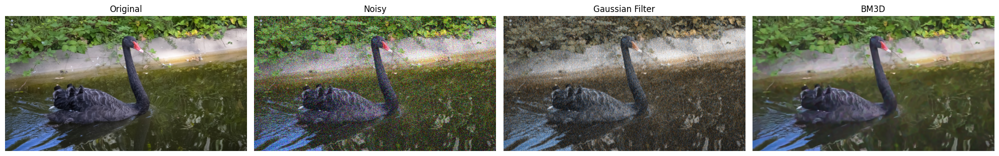

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

images = [
    clean_frames[0],
    noisy_frames[0],
    gaussian_frames[0],
    bm3d_frame
]

titles = [
    "Original",
    "Noisy",
    "Gaussian Filter",
    "BM3D"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
bm3d_psnr = peak_signal_noise_ratio(
    clean_frames[0],
    np.clip(bm3d_frame, 0, 1),
    data_range=1.0
)

bm3d_ssim = structural_similarity(
    clean_frames[0],
    np.clip(bm3d_frame, 0, 1),
    channel_axis=-1,
    data_range=1.0
)

print("Frame 0 Results")
print("--------------------------")
print("Noisy PSNR:", round(psnr_scores[0], 2))
print("Gaussian PSNR:", round(gaussian_psnr[0], 2))
print("BM3D PSNR:", round(bm3d_psnr, 2))

print()
print("Noisy SSIM:", round(ssim_scores[0], 4))
print("Gaussian SSIM:", round(gaussian_ssim[0], 4))
print("BM3D SSIM:", round(bm3d_ssim, 4))

Frame 0 Results
--------------------------
Noisy PSNR: 14.84
Gaussian PSNR: 21.52
BM3D PSNR: 27.38

Noisy SSIM: 0.1551
Gaussian SSIM: 0.4309
BM3D SSIM: 0.7445


In [ ]:
bm3d_frames = [bm3d_frame]

for i in range(1, len(noisy_frames)):
    denoised = bm3d.bm3d_rgb(
        noisy_frames[i],
        sigma_psd=0.2
    )

    bm3d_frames.append(np.clip(denoised, 0, 1))
    print(f"Processed frame {i + 1}/{len(noisy_frames)}")

bm3d_frames = np.stack(bm3d_frames)


print("BM3D video shape:", bm3d_frames.shape)

Processed frame 2/10
Processed frame 3/10
Processed frame 4/10
Processed frame 5/10
Processed frame 6/10
Processed frame 7/10
Processed frame 8/10
Processed frame 9/10
Processed frame 10/10
BM3D video shape: (10, 480, 854, 3)


In [ ]:
bm3d_psnr_scores = []
bm3d_ssim_scores = []

for i in range(len(clean_frames)):

    psnr = peak_signal_noise_ratio(
        clean_frames[i],
        bm3d_frames[i],
        data_range=1.0
    )

    ssim = structural_similarity(
        clean_frames[i],
        bm3d_frames[i],
        channel_axis=-1,
        data_range=1.0
    )

    bm3d_psnr_scores.append(psnr)
    bm3d_ssim_scores.append(ssim)

print("Average Results (10 Frames)")
print("---------------------------")

print(f"{'Method':<12} {'PSNR (dB)':<12} {'SSIM':<10}")

print(f"{'Noisy':<12} {np.mean(psnr_scores):<12.2f} {np.mean(ssim_scores):<10.4f}")
print(f"{'Gaussian':<12} {np.mean(gaussian_psnr):<12.2f} {np.mean(gaussian_ssim):<10.4f}")
print(f"{'BM3D':<12} {np.mean(bm3d_psnr_scores):<12.2f} {np.mean(bm3d_ssim_scores):<10.4f}")

Average Results (10 Frames)
---------------------------
Method       PSNR (dB)    SSIM      
Noisy        14.84        0.1587    
Gaussian     21.54        0.4356    
BM3D         27.34        0.7510    


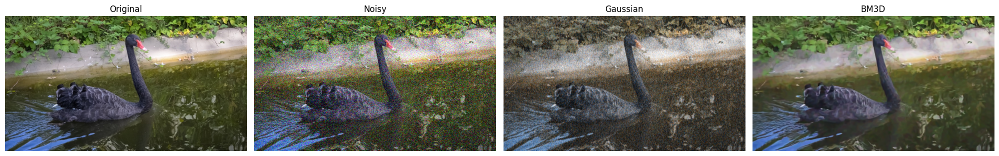

In [ ]:
frame_idx = 4

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

images = [
    clean_frames[frame_idx],
    noisy_frames[frame_idx],
    gaussian_frames[frame_idx],
    bm3d_frames[frame_idx]
]

titles = [
    "Original",
    "Noisy",
    "Gaussian",
    "BM3D"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

RESULTS_DIR = Path("/content/FrameRevive/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Results directory:", RESULTS_DIR)

Results directory: /content/FrameRevive/results


In [ ]:
import imageio.v2 as imageio
from IPython.display import Video, display

videos = {
    "Original": clean_frames,
    "Noisy": noisy_frames,
    "Gaussian": gaussian_frames,
    "BM3D": bm3d_frames
}

for name, frames_array in videos.items():
    output_path = str(RESULTS_DIR / f"{name.lower()}.mp4")

    frames_uint8 = (np.clip(frames_array, 0, 1) * 255).astype(np.uint8)

    imageio.mimsave(
        output_path,
        frames_uint8,
        fps=5,
        macro_block_size=2
    )

    print(f"\n{name} Video:")
    display(Video(output_path, embed=True))


Original Video:



Noisy Video:



Gaussian Video:



BM3D Video:


In [ ]:
from pathlib import Path
import numpy as np
from PIL import Image

frames_dir = Path("/content/FrameRevive/data/DAVIS/JPEGImages/480p/blackswan")

frames_path = sorted(frames_dir.glob("*.jpg"))

video_frames = []

for path in frames_path[:30]:
  frame = np.array(Image.open(path).convert("RGB"))
  video_frames.append(frame)

video_frames = np.stack(video_frames)

print("Video shape:", video_frames.shape)
print("Data type:", video_frames.dtype)
print("Number of frames:", len(video_frames))

Video shape: (30, 480, 854, 3)
Data type: uint8
Number of frames: 30


In [ ]:
# Step 1: Normalize pixel values
clean_video = video_frames.astype(np.float32) / 255.0

# Step 2: Define noise strength
noise_sigma = 0.2

# Step 3: Generate reproducible Gaussian noise
rng = np.random.default_rng(42)

noise = rng.normal(
    loc=0,
    scale=noise_sigma,
    size=clean_video.shape
)

# Step 4: Add noise to every frame
noisy_video = np.clip(
    clean_video + noise,
    0,
    1
).astype(np.float32)

print("Clean video shape:", clean_video.shape)
print("Noisy video shape:", noisy_video.shape)
print("Pixel value range:", noisy_video.min(), noisy_video.max())

Clean video shape: (30, 480, 854, 3)
Noisy video shape: (30, 480, 854, 3)
Pixel value range: 0.0 1.0


In [ ]:
import imageio.v2 as imageio
from IPython.display import Video, display

output_path = "/content/FrameRevive/results/noisy_30frames.mp4"

frames_uint8 = (noisy_video * 255).astype(np.uint8)

imageio.mimsave(
    output_path,
    frames_uint8,
    fps=24,
    macro_block_size=2
)

display(Video(output_path, embed=True))

In [ ]:
%cd /content/FrameRevive

!git clone https://github.com/m-tassano/fastdvdnet.git

from pathlib import Path

model_dir = Path("/content/FrameRevive/fastdvdnet")

print("Repository exists:", model_dir.exists())
print("Model weights exist:", (model_dir / "model_clipped_noise.pth").exists())

/content/FrameRevive
Cloning into 'fastdvdnet'...
remote: Enumerating objects: 145, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (27/27), done.
remote: Total 145 (delta 21), reused 12 (delta 9), pack-reused 109 (from 1)
Receiving objects: 100% (145/145), 34.97 MiB | 20.94 MiB/s, done.
Resolving deltas: 100% (71/71), done.
Repository exists: True
Model weights exist: True


In [ ]:
import sys
import torch
from pathlib import Path

model_dir = Path("/content/FrameRevive/fastdvdnet")
sys.path.insert(0, str(model_dir))

from models import FastDVDnet

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create model architecture
model = FastDVDnet(num_input_frames=5)

# Load pretrained checkpoint
checkpoint = torch.load(
    model_dir / "model_clipped_noise.pth",
    map_location="cpu",
    weights_only=True
)

# Remove DataParallel prefix
fixed_checkpoint = {
    key.removeprefix("module."): value
    for key, value in checkpoint.items()
}

# Load pretrained weights into the model
model.load_state_dict(fixed_checkpoint)

# Move model to GPU and switch to inference mode
model = model.to(device)
model.eval()

print("FastDVDnet loaded successfully!")
print("Running on:", device)

FastDVDnet loaded successfully!
Running on: cuda


In [ ]:
input_frames = noisy_video[0:5]

input_tensor = torch.from_numpy(input_frames)

input_tensor = input_tensor.permute(0,3,1,2)

input_tensor = input_tensor.unsqueeze(0)

input_tensor = input_tensor.to(device)

print("Original shape:", input_frames.shape)
print("Model input shape:", input_tensor.shape)
print("Device:", input_tensor.device)

Original shape: (5, 480, 854, 3)
Model input shape: torch.Size([1, 5, 3, 480, 854])
Device: cuda:0


In [ ]:
import torch.nn.functional as F

# Original input dimensions
B, T, C, H, W = input_tensor.shape

# Calculate padding needed for multiples of 8
pad_h = (8 - H % 8) % 8
pad_w = (8 - W % 8) % 8

# Flatten the five RGB frames into 15 channels
model_input = input_tensor.reshape(B, T * C, H, W)

# Pad on the right and bottom
model_input = F.pad(
    model_input,
    (0, pad_w, 0, pad_h),
    mode="reflect"
)

# Create noise map matching padded dimensions
noise_map = torch.full(
    (B, 1, H + pad_h, W + pad_w),
    0.2,
    device=device
)

# Run inference
with torch.inference_mode():
    denoised_tensor = model(model_input, noise_map)

# Crop back to original resolution
denoised_tensor = denoised_tensor[:, :, :H, :W]

print("Padding added:", pad_h, pad_w)
print("Padded input:", model_input.shape)
print("Denoised output:", denoised_tensor.shape)

Padding added: 0 2
Padded input: torch.Size([1, 15, 480, 856])
Denoised output: torch.Size([1, 3, 480, 854])


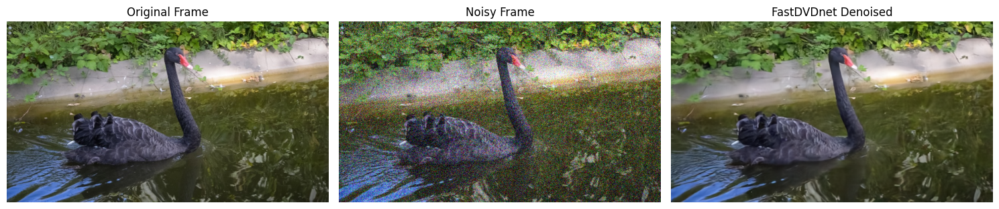

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Convert model output from PyTorch tensor to NumPy image
fastdvdnet_frame = (
    denoised_tensor
    .squeeze(0)
    .permute(1, 2, 0)
    .cpu()
    .numpy()
)

# Ensure pixel values are between 0 and 1
fastdvdnet_frame = np.clip(fastdvdnet_frame, 0, 1)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(clean_video[2])
axes[0].set_title("Original Frame")

axes[1].imshow(noisy_video[2])
axes[1].set_title("Noisy Frame")

axes[2].imshow(fastdvdnet_frame)
axes[2].set_title("FastDVDnet Denoised")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Compare noisy frame against original
noisy_psnr = peak_signal_noise_ratio(
    clean_video[2], noisy_video[2], data_range=1.0
)

noisy_ssim = structural_similarity(
    clean_video[2], noisy_video[2],
    channel_axis=-1, data_range=1.0
)

# Compare FastDVDnet output against original
fast_psnr = peak_signal_noise_ratio(
    clean_video[2], fastdvdnet_frame, data_range=1.0
)

fast_ssim = structural_similarity(
    clean_video[2], fastdvdnet_frame,
    channel_axis=-1, data_range=1.0
)

print(f"Noisy      → PSNR: {noisy_psnr:.2f} dB | SSIM: {noisy_ssim:.4f}")
print(f"FastDVDnet → PSNR: {fast_psnr:.2f} dB | SSIM: {fast_ssim:.4f}")

Noisy      → PSNR: 14.84 dB | SSIM: 0.1575
FastDVDnet → PSNR: 29.37 dB | SSIM: 0.8137


In [ ]:
import time
import torch.nn.functional as F

fastdvdnet_frames = []

start_time = time.perf_counter()

with torch.inference_mode():
    for i in range(len(noisy_video)):

        # Select five neighboring frames
        indices = [
            min(max(j, 0), len(noisy_video) - 1)
            for j in range(i - 2, i + 3)
        ]

        window = noisy_video[indices]

        # Convert to tensor: (5, H, W, 3) -> (1, 15, H, W)
        tensor = torch.from_numpy(window).permute(0, 3, 1, 2)
        tensor = tensor.reshape(1, 15, *tensor.shape[-2:]).to(device)

        H, W = tensor.shape[-2:]
        pad_h = (8 - H % 8) % 8
        pad_w = (8 - W % 8) % 8

        tensor = F.pad(tensor, (0, pad_w, 0, pad_h), mode="reflect")

        noise_map = torch.full(
            (1, 1, H + pad_h, W + pad_w),
            0.2,
            device=device
        )

        output = model(tensor, noise_map)

        # Crop and convert back to NumPy
        frame = (
            output[:, :, :H, :W]
            .squeeze(0)
            .permute(1, 2, 0)
            .clamp(0, 1)
            .cpu()
            .numpy()
        )

        fastdvdnet_frames.append(frame)

torch.cuda.synchronize() if device.type == "cuda" else None

elapsed = time.perf_counter() - start_time

fastdvdnet_frames = np.stack(fastdvdnet_frames)

print("Output shape:", fastdvdnet_frames.shape)
print(f"Total inference time: {elapsed:.2f} seconds")
print(f"Throughput: {len(fastdvdnet_frames) / elapsed:.2f} FPS")

Output shape: (30, 480, 854, 3)
Total inference time: 9.53 seconds
Throughput: 3.15 FPS


In [ ]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import numpy as np

def evaluate_video(clean, restored):
    psnr_scores = []
    ssim_scores = []

    for i in range(len(clean)):
        psnr = peak_signal_noise_ratio(
            clean[i],
            restored[i],
            data_range=1.0
        )

        ssim = structural_similarity(
            clean[i],
            restored[i],
            channel_axis=-1,
            data_range=1.0
        )

        psnr_scores.append(psnr)
        ssim_scores.append(ssim)

    return np.mean(psnr_scores), np.mean(ssim_scores)


# Evaluate noisy video
noisy_psnr, noisy_ssim = evaluate_video(
    clean_video, noisy_video
)

# Evaluate FastDVDnet
fast_psnr, fast_ssim = evaluate_video(
    clean_video, fastdvdnet_frames
)

print(f"Noisy Video: PSNR={noisy_psnr:.2f}, SSIM={noisy_ssim:.4f}")
print(f"FastDVDnet: PSNR={fast_psnr:.2f}, SSIM={fast_ssim:.4f}")

Noisy Video: PSNR=14.84, SSIM=0.1563
FastDVDnet: PSNR=29.06, SSIM=0.7940


Clean crop shape: (256, 256, 3)
Noisy crop shape: (256, 256, 3)


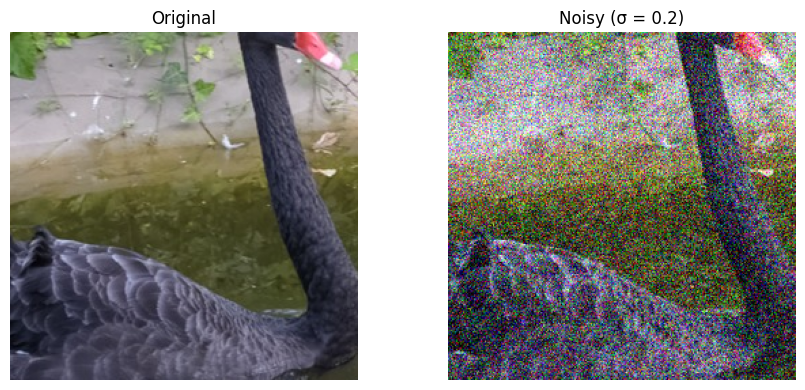

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Select frame 2 from our existing video
frame_idx = 2

# Use a 256 × 256 crop for initial diffusion testing
clean_crop = clean_video[frame_idx, 100:356, 250:506]
noisy_crop = noisy_video[frame_idx, 100:356, 250:506]

print("Clean crop shape:", clean_crop.shape)
print("Noisy crop shape:", noisy_crop.shape)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(clean_crop)
axes[0].set_title("Original")

axes[1].imshow(noisy_crop)
axes[1].set_title("Noisy (σ = 0.2)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch

print("GPU:", torch.cuda.get_device_name(0))

free_memory, total_memory = torch.cuda.mem_get_info()

print(f"Free GPU memory: {free_memory / 1024**3:.2f} GB")
print(f"Total GPU memory: {total_memory / 1024**3:.2f} GB")

GPU: Tesla T4
Free GPU memory: 13.91 GB
Total GPU memory: 14.56 GB


In [ ]:

import numpy as np
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

for name in ["clean_video", "noisy_video"]:
    if name in globals():
        arr = globals()[name]
        print(f"{name}: shape={arr.shape}, dtype={arr.dtype}")
    else:
        print(f"{name}: NOT FOUND")


GPU available: True
GPU: Tesla T4
clean_video: shape=(30, 480, 854, 3), dtype=float32
noisy_video: shape=(30, 480, 854, 3), dtype=float32


Crop shape: (256, 256, 3)
Noisy PSNR: 14.58 dB
Noisy SSIM: 0.1406


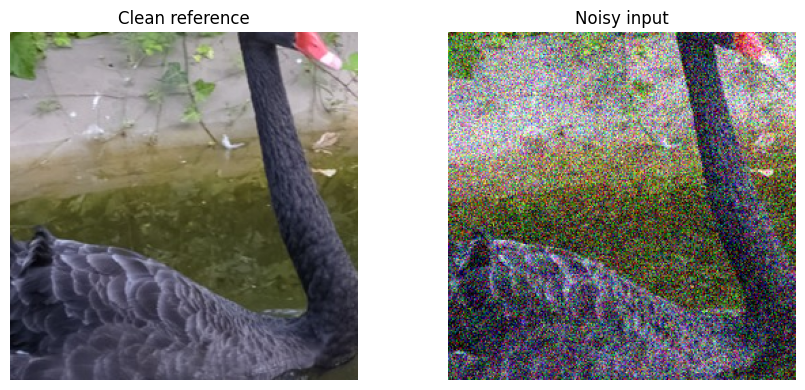

In [ ]:

import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

# Extract matching 256x256 crops from frame 3
clean_crop = clean_video[2, 100:356, 250:506].copy()
noisy_crop = noisy_video[2, 100:356, 250:506].copy()

# Calculate initial quality
noisy_psnr = peak_signal_noise_ratio(
    clean_crop, noisy_crop, data_range=1.0
)

noisy_ssim = structural_similarity(
    clean_crop, noisy_crop,
    channel_axis=2, data_range=1.0
)

print("Crop shape:", noisy_crop.shape)
print(f"Noisy PSNR: {noisy_psnr:.2f} dB")
print(f"Noisy SSIM: {noisy_ssim:.4f}")

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(clean_crop)
axes[0].set_title("Clean reference")

axes[1].imshow(noisy_crop)
axes[1].set_title("Noisy input")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import torch

# Convert NumPy image (H, W, C) to PyTorch tensor (B, C, H, W)
noisy_tensor = torch.from_numpy(noisy_crop).permute(2, 0, 1).unsqueeze(0)
noisy_tensor = noisy_tensor.float().to("cuda")

print("Tensor shape:", noisy_tensor.shape)
print("Tensor dtype:", noisy_tensor.dtype)
print("Tensor device:", noisy_tensor.device)
print("Pixel range:", noisy_tensor.min().item(), noisy_tensor.max().item())


Tensor shape: torch.Size([1, 3, 256, 256])
Tensor dtype: torch.float32
Tensor device: cuda:0
Pixel range: 0.0 1.0


In [ ]:

import sys
import torch
import numpy as np
import subprocess
from pathlib import Path

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("NumPy:", np.__version__)
print("GPU:", torch.cuda.get_device_name(0))

repo = Path("/content/ddrm")

if not repo.exists():
    subprocess.run(
        ["git", "clone", "https://github.com/bahjat-kawar/ddrm.git", str(repo)],
        check=True
    )

print("\nDDRM repository:", repo)
print("Environment file exists:", (repo / "environment.yml").exists())
print("Main script exists:", (repo / "main.py").exists())


Python: 3.13.16
PyTorch: 2.11.0+cu130
CUDA: 13.0
NumPy: 2.1.3
GPU: Tesla T4

DDRM repository: /content/ddrm
Environment file exists: False
Main script exists: False


In [ ]:

import importlib.util
import sys
from pathlib import Path

diffusion_path = Path("/content/ddrm/models/diffusion.py")

spec = importlib.util.spec_from_file_location(
    "ddrm_diffusion_test",
    diffusion_path
)

module = importlib.util.module_from_spec(spec)

try:
    sys.modules[spec.name] = module
    spec.loader.exec_module(module)

    print("SUCCESS: DDRM diffusion module loaded!")
    print("Module:", module.__file__)

except Exception as e:
    print("FAILED:", type(e).__name__, str(e))


FAILED: FileNotFoundError [Errno 2] No such file or directory: '/content/ddrm/models/diffusion.py'


In [ ]:

from pathlib import Path
import yaml

config_path = Path("/content/ddrm/configs/imagenet_256.yml")

print("Config exists:", config_path.exists())

if config_path.exists():
    with open(config_path) as f:
        config = yaml.safe_load(f)

    for section in ["model", "diffusion", "data", "sampling"]:
        print(f"\n=== {section.upper()} ===")
        print(config.get(section, "Not specified"))


Config exists: False


In [ ]:

from pathlib import Path
import subprocess

checkpoint = Path(
    "/content/ddrm/exp/logs/imagenet/256x256_diffusion_uncond.pt"
)

checkpoint.parent.mkdir(parents=True, exist_ok=True)

url = (
    "https://openaipublic.blob.core.windows.net/"
    "diffusion/jul-2021/256x256_diffusion_uncond.pt"
)

if checkpoint.exists() and checkpoint.stat().st_size > 2_000_000_000:
    print("Checkpoint already downloaded.")
else:
    subprocess.run(
        [
            "wget", "-c",
            "--show-progress",
            "-O", str(checkpoint),
            url
        ],
        check=True
    )

print("\nDownload complete!")
print("Checkpoint:", checkpoint)
print("Size:", round(checkpoint.stat().st_size / 1024**3, 2), "GB")



Download complete!
Checkpoint: /content/ddrm/exp/logs/imagenet/256x256_diffusion_uncond.pt
Size: 2.06 GB


In [ ]:

import subprocess
import sys

code = r'''
import torch
import yaml
from guided_diffusion.script_util import create_model

with open("configs/imagenet_256.yml") as f:
    config = yaml.safe_load(f)

model_config = config["model"]

print("Initializing OpenAI diffusion model...")

model = create_model(
    image_size=model_config["image_size"],
    num_channels=model_config["num_channels"],
    num_res_blocks=model_config["num_res_blocks"],
    channel_mult="",
    learn_sigma=model_config["learn_sigma"],
    class_cond=model_config["class_cond"],
    use_checkpoint=False,
    attention_resolutions=model_config["attention_resolutions"],
    num_heads=model_config["num_heads"],
    num_head_channels=model_config["num_head_channels"],
    num_heads_upsample=model_config["num_heads_upsample"],
    use_scale_shift_norm=model_config["use_scale_shift_norm"],
    dropout=model_config["dropout"],
    resblock_updown=model_config["resblock_updown"],
    use_fp16=model_config["use_fp16"],
    use_new_attention_order=model_config["use_new_attention_order"]
)

print("Loading pretrained weights...")

weights = torch.load(
    "exp/logs/imagenet/256x256_diffusion_uncond.pt",
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(weights, strict=True)
model = model.to("cuda").eval()

print("SUCCESS: DDRM diffusion model loaded!")
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)
'''

result = subprocess.run(
    [sys.executable, "-c", code],
    cwd="/content/ddrm",
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr[-3000:])

print("Exit code:", result.returncode)



Traceback (most recent call last):
  File "<string>", line 4, in <module>
    from guided_diffusion.script_util import create_model
ModuleNotFoundError: No module named 'guided_diffusion'

Exit code: 1


In [ ]:

import numpy as np
import torch
from pathlib import Path

# noisy_crop and clean_crop are already in your notebook
assert noisy_crop.shape == (256, 256, 3)
assert clean_crop.shape == (256, 256, 3)

input_dir = Path("/content/ddrm/frame_revive")
input_dir.mkdir(parents=True, exist_ok=True)

# Convert HWC -> CHW and add batch dimension
noisy_tensor = torch.from_numpy(
    np.ascontiguousarray(noisy_crop.transpose(2, 0, 1))
).float().unsqueeze(0)

clean_tensor = torch.from_numpy(
    np.ascontiguousarray(clean_crop.transpose(2, 0, 1))
).float().unsqueeze(0)

torch.save(noisy_tensor, input_dir / "noisy.pt")
torch.save(clean_tensor, input_dir / "clean.pt")

print("Noisy tensor:", noisy_tensor.shape)
print("Clean tensor:", clean_tensor.shape)
print("Noise level:", 0.2)
print("Input files saved successfully.")


Noisy tensor: torch.Size([1, 3, 256, 256])
Clean tensor: torch.Size([1, 3, 256, 256])
Noise level: 0.2
Input files saved successfully.


In [ ]:

from pathlib import Path

root = Path("/content/ddrm")

for filename in ["main.py", "runners/diffusion.py"]:
    path = root / filename

    if not path.exists():
        continue

    lines = path.read_text().splitlines()

    print(f"\n=== {filename} ===")

    for i, line in enumerate(lines):
        if (
            "def sample(" in line
            or "def sample_image(" in line
            or "def sample_sequence(" in line
            or "def sample_generalized(" in line
            or "def sample_ddrm(" in line
            or "def sample_simplified(" in line
            or "def sample_image_denoising(" in line
            or "def sample_image_inverse(" in line
            or "def sample_image_general(" in line
            or "def sample_image_restoration(" in line
            or "def sample_image_ddrm(" in line
            or "def sample_image_deblur(" in line
            or "def sample_image_sr(" in line
            or "def sample_image_inpaint(" in line
            or "def sample_image_colorization(" in line
            or "def sample_image_denoise(" in line
            or "def sample_image_denoiser(" in line
            or "def sample_image_restorer(" in line
            or "def sample_image_restore(" in line
            or "def sample_image_inverse_problem(" in line
            or "def sample_image_inverse_problems(" in line
            or "def sample_image_reconstruction(" in line
            or "def sample_image_reconstruct(" in line
            or "def sample_image_recovery(" in line
            or "def sample_image_recover(" in line
            or "def sample_image_recon(" in line
            or "def sample_image_restoration_ddrm(" in line
            or "def sample_image_ddrm_restoration(" in line
            or "def sample_image_ddrm_denoising(" in line
            or "def sample_image_ddrm_denoise(" in line
            or "def sample_image_ddrm_inverse(" in line
            or "def sample_image_ddrm_inverse_problem(" in line
            or "def sample_image_ddrm_inverse_problems(" in line
            or "def sample_image_ddrm_reconstruction(" in line
            or "def sample_image_ddrm_reconstruct(" in line
            or "def sample_image_ddrm_recovery(" in line
            or "def sample_image_ddrm_recover(" in line
            or "def sample_image_ddrm_recon(" in line
        ):
            start = max(0, i - 2)
            end = min(len(lines), i + 12)

            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")


In [ ]:

import subprocess
import sys

code = r'''
import time
import torch
import yaml
from types import SimpleNamespace
from guided_diffusion.script_util import create_model
from functions.svd_replacement import Denoising
from functions.denoising import efficient_generalized_steps

torch.manual_seed(42)
device = torch.device("cuda")

with open("configs/imagenet_256.yml") as f:
    cfg = yaml.safe_load(f)

m = cfg["model"]

model = create_model(
    image_size=m["image_size"],
    num_channels=m["num_channels"],
    num_res_blocks=m["num_res_blocks"],
    channel_mult="",
    learn_sigma=m["learn_sigma"],
    class_cond=m["class_cond"],
    use_checkpoint=False,
    attention_resolutions=m["attention_resolutions"],
    num_heads=m["num_heads"],
    num_head_channels=m["num_head_channels"],
    num_heads_upsample=m["num_heads_upsample"],
    use_scale_shift_norm=m["use_scale_shift_norm"],
    dropout=m["dropout"],
    resblock_updown=m["resblock_updown"],
    use_fp16=False,
    use_new_attention_order=m["use_new_attention_order"]
)

weights = torch.load(
    "exp/logs/imagenet/256x256_diffusion_uncond.pt",
    map_location="cpu",
    weights_only=True
)
model.load_state_dict(weights)
model = model.to(device).float().eval()

# Existing noisy observation, not newly generated noise
noisy = torch.load(
    "frame_revive/noisy.pt",
    map_location=device,
    weights_only=True
)

# DDRM works in [-1, 1]
y_0 = (noisy * 2 - 1).reshape(1, -1)

# Identity degradation: Gaussian denoising
H_funcs = Denoising(3, 256, device)

# Linear beta schedule from the DDRM config
betas = torch.linspace(0.0001, 0.02, 1000, device=device)

# 20 sampling steps
seq = range(0, 1000, 20)  # 50 sampling steps
# Noise sigma in [-1, 1] scale
sigma_0 = 0.4

x = torch.randn(1, 3, 256, 256, device=device)

print("Starting 20-step DDRM denoising...", flush=True)

torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()

with torch.inference_mode():
    result = efficient_generalized_steps(
        x, seq, model, betas, H_funcs, y_0, sigma_0,
        etaB=1.0,
        etaA=0.85,
        etaC=0.85
    )

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

restored = ((result[0][-1] + 1) / 2).clamp(0, 1)

torch.save(restored.cpu(), "frame_revive/ddrm_50steps.pt")
print("SUCCESS: Denoising completed!")
print("Runtime:", round(elapsed, 2), "seconds")
print("Peak GPU memory:",
      round(torch.cuda.max_memory_allocated() / 1024**3, 2), "GB")
'''

result = subprocess.run(
    [sys.executable, "-c", code],
    cwd="/content/ddrm",
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr[-4000:])

print("Exit code:", result.returncode)



Traceback (most recent call last):
  File "<string>", line 6, in <module>
    from guided_diffusion.script_util import create_model
ModuleNotFoundError: No module named 'guided_diffusion'

Exit code: 1


In [ ]:
from pathlib import Path

base = Path("/content/ddrm")

files = {
    "DDRM configuration": base / "configs/imagenet_256.yml",
    "Pretrained checkpoint": base / "exp/logs/imagenet/256x256_diffusion_uncond.pt",
    "Noisy image": base / "frame_revive/noisy.pt",
    "Restored image": base / "frame_revive/ddrm_50steps.pt",
}

for name, path in files.items():
    if path.exists():
        size = path.stat().st_size / (1024**3)
        print(f"✅ {name}: EXISTS ({size:.2f} GB)")
    else:
        print(f"❌ {name}: MISSING")

❌ DDRM configuration: MISSING
✅ Pretrained checkpoint: EXISTS (2.06 GB)
✅ Noisy image: EXISTS (0.00 GB)
❌ Restored image: MISSING


In [ ]:

import numpy as np
from pathlib import Path

video_dir = Path("/content/ddrm/frame_revive")
video_dir.mkdir(parents=True, exist_ok=True)

# Same crop coordinates used in our DDRM image experiment
clean_video_crops = clean_video[:, 100:356, 250:506, :]
noisy_video_crops = noisy_video[:, 100:356, 250:506, :]

assert clean_video_crops.shape == (30, 256, 256, 3)
assert noisy_video_crops.shape == (30, 256, 256, 3)

np.save(video_dir / "clean_video_crops.npy", clean_video_crops)
np.save(video_dir / "noisy_video_crops.npy", noisy_video_crops)

# Every fourth frame is a keyframe
keyframe_indices = list(range(0, 30, 4))

print("Clean video:", clean_video_crops.shape)
print("Noisy video:", noisy_video_crops.shape)
print("Keyframe indices:", keyframe_indices)
print("Number of keyframes:", len(keyframe_indices))
print("Video crops saved successfully!")


Clean video: (30, 256, 256, 3)
Noisy video: (30, 256, 256, 3)
Keyframe indices: [0, 4, 8, 12, 16, 20, 24, 28]
Number of keyframes: 8
Video crops saved successfully!


In [ ]:

import subprocess
import sys

code = r'''
import time
import numpy as np
import torch
import yaml
from pathlib import Path
from guided_diffusion.script_util import create_model
from functions.svd_replacement import Denoising
from functions.denoising import efficient_generalized_steps

device = torch.device("cuda")
torch.manual_seed(42)

folder = Path("frame_revive")
noisy_video = np.load(folder / "noisy_video_crops.npy")
keyframes = list(range(0, len(noisy_video), 4))

with open("configs/imagenet_256.yml") as f:
    m = yaml.safe_load(f)["model"]

print("Loading DDRM model...", flush=True)

model = create_model(
    image_size=m["image_size"],
    num_channels=m["num_channels"],
    num_res_blocks=m["num_res_blocks"],
    channel_mult="",
    learn_sigma=m["learn_sigma"],
    class_cond=m["class_cond"],
    use_checkpoint=False,
    attention_resolutions=m["attention_resolutions"],
    num_heads=m["num_heads"],
    num_head_channels=m["num_head_channels"],
    num_heads_upsample=m["num_heads_upsample"],
    use_scale_shift_norm=m["use_scale_shift_norm"],
    dropout=m["dropout"],
    resblock_updown=m["resblock_updown"],
    use_fp16=False,
    use_new_attention_order=m["use_new_attention_order"]
)

weights = torch.load(
    "exp/logs/imagenet/256x256_diffusion_uncond.pt",
    map_location="cpu",
    weights_only=True
)
model.load_state_dict(weights)
del weights

model = model.to(device).float().eval()

H_funcs = Denoising(3, 256, device)
betas = torch.linspace(0.0001, 0.02, 1000, device=device)
seq = range(0, 1000, 50)  # 20 sampling steps
sigma_0 = 0.4

output_dir = folder / "restored_keyframes"
output_dir.mkdir(exist_ok=True)

torch.cuda.reset_peak_memory_stats()
start_total = time.perf_counter()

for i in keyframes:
    start = time.perf_counter()

    frame = torch.from_numpy(
        np.ascontiguousarray(noisy_video[i].transpose(2, 0, 1))
    ).float().unsqueeze(0).to(device)

    y_0 = (frame * 2 - 1).reshape(1, -1)
    x = torch.randn(1, 3, 256, 256, device=device)

    with torch.inference_mode():
        result = efficient_generalized_steps(
            x, seq, model, betas, H_funcs, y_0, sigma_0,
            etaB=1.0,
            etaA=0.85,
            etaC=0.85
        )

    restored = ((result[0][-1] + 1) / 2).clamp(0, 1)

    np.save(
        output_dir / f"frame_{i:03d}.npy",
        restored.squeeze(0).permute(1, 2, 0).cpu().numpy()
    )

    torch.cuda.synchronize()
    print(
        f"Restored keyframe {i:02d} | "
        f"{time.perf_counter() - start:.2f}s",
        flush=True
    )

print("\nAll keyframes restored!")
print("Total time:", round(time.perf_counter() - start_total, 2), "seconds")
print(
    "Peak GPU memory:",
    round(torch.cuda.max_memory_allocated() / 1024**3, 2),
    "GB"
)
'''

result = subprocess.run(
    [sys.executable, "-u", "-c", code],
    cwd="/content/ddrm",
    capture_output=True,
    text=True
)

print(result.stdout)

if result.stderr:
    print(result.stderr[-3000:])

print("Exit code:", result.returncode)


Loading DDRM model...
Restored keyframe 00 | 18.14s
Restored keyframe 04 | 17.25s
Restored keyframe 08 | 17.64s
Restored keyframe 12 | 17.54s
Restored keyframe 16 | 17.36s
Restored keyframe 20 | 17.28s
Restored keyframe 24 | 17.35s
Restored keyframe 28 | 17.41s

All keyframes restored!
Total time: 139.97 seconds
Peak GPU memory: 2.6 GB

it [00:03,  1.14it/s]
5it [00:04,  1.14it/s]
6it [00:05,  1.14it/s]
7it [00:06,  1.14it/s]
8it [00:07,  1.14it/s]
9it [00:07,  1.14it/s]
10it [00:08,  1.14it/s]
11it [00:09,  1.14it/s]
12it [00:10,  1.13it/s]
13it [00:11,  1.13it/s]
14it [00:12,  1.13it/s]
15it [00:13,  1.13it/s]
16it [00:14,  1.13it/s]
17it [00:14,  1.13it/s]
18it [00:15,  1.13it/s]
19it [00:16,  1.13it/s]
20it [00:17,  1.13it/s]
20it [00:17,  1.13it/s]

0it [00:00, ?it/s]
1it [00:00,  1.13it/s]
2it [00:01,  1.13it/s]
3it [00:02,  1.13it/s]
4it [00:03,  1.13it/s]
5it [00:04,  1.14it/s]
6it [00:05,  1.14it/s]
7it [00:06,  1.14it/s]
8it [00:07,  1.14it/s]
9it [00:07,  1.14it/s]
10it [00:

In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Source: restored DDRM keyframes
source = Path("/content/ddrm/frame_revive/restored_keyframes")

# Destination: permanent Google Drive backup
destination = Path("/content/drive/MyDrive/FrameRevive/restored_keyframes")

# Verify all 8 keyframes exist
files = sorted(source.glob("frame_*.npy"))

print("Restored keyframes found:", len(files))

if len(files) == 8:
    destination.mkdir(parents=True, exist_ok=True)

    for file in files:
        shutil.copy2(file, destination / file.name)

    print("Backup completed successfully!")
    print("Saved to:", destination)
    print("Files backed up:", len(list(destination.glob("frame_*.npy"))))
else:
    print("Expected 8 keyframes. Check the DDRM inference output.")

Mounted at /content/drive
Restored keyframes found: 8
Backup completed successfully!
Saved to: /content/drive/MyDrive/FrameRevive/restored_keyframes
Files backed up: 8


In [ ]:
import torch
from torchvision.models.optical_flow import (
    raft_small,
    Raft_Small_Weights
)

# Use the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained RAFT-Small weights
weights = Raft_Small_Weights.DEFAULT

# Initialize the model
raft = raft_small(
    weights=weights,
    progress=True
).to(device)

# Set evaluation mode (we are not training the model)
raft.eval()

print("RAFT loaded successfully!")
print("Model: RAFT-Small")
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Downloading: "https://download.pytorch.org/models/raft_small_C_T_V2-01064c6d.pth" to /root/.cache/torch/hub/checkpoints/raft_small_C_T_V2-01064c6d.pth


100%|██████████| 3.82M/3.82M [00:00<00:00, 33.4MB/s]

RAFT loaded successfully!
Model: RAFT-Small
Device: cuda
GPU: Tesla T4


Optical flow shape: torch.Size([1, 2, 256, 256])


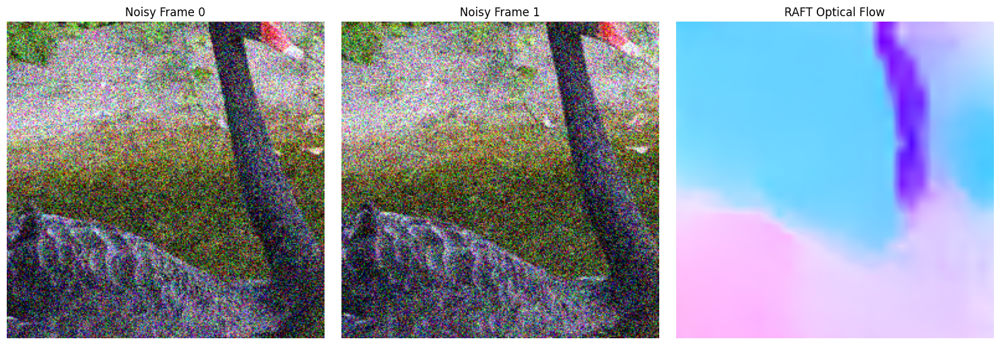

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torchvision.utils import flow_to_image

# Load our 30 noisy video frames
noisy_frames = np.load(
    "/content/ddrm/frame_revive/noisy_video_crops.npy"
)

# Convert a frame from NumPy to a PyTorch tensor
def prepare_frame(frame):
    tensor = torch.from_numpy(
        np.ascontiguousarray(frame.transpose(2, 0, 1))
    ).float().unsqueeze(0)

    # RAFT expects pixel values in [-1, 1]
    tensor = tensor * 2 - 1

    return tensor.to(device)

# Prepare two consecutive frames
frame0 = prepare_frame(noisy_frames[0])
frame1 = prepare_frame(noisy_frames[1])

# Estimate motion from frame 0 to frame 1
with torch.inference_mode():
    flow_predictions = raft(frame0, frame1)

# RAFT returns multiple predictions; use the final one
flow = flow_predictions[-1]

print("Optical flow shape:", flow.shape)

# Convert flow vectors into a visualization
flow_rgb = flow_to_image(flow.cpu())[0]
flow_rgb = flow_rgb.permute(1, 2, 0).numpy()

# Display the frames and estimated motion
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(noisy_frames[0])
axes[0].set_title("Noisy Frame 0")

axes[1].imshow(noisy_frames[1])
axes[1].set_title("Noisy Frame 1")

axes[2].imshow(flow_rgb)
axes[2].set_title("RAFT Optical Flow")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import time
import numpy as np
import torch
from pathlib import Path

folder = Path("/content/ddrm/frame_revive")

noisy_frames = np.load(folder / "noisy_video_crops.npy")

# Convert all frames into RAFT-compatible tensors
frames = torch.from_numpy(
    np.ascontiguousarray(noisy_frames.transpose(0, 3, 1, 2))
).float().to(device)

frames = frames * 2 - 1

forward_flows = []
backward_flows = []

raft.eval()

start = time.perf_counter()

with torch.inference_mode():
    for i in range(len(frames) - 1):

        # Motion from frame i to frame i+1
        forward = raft(
            frames[i:i+1],
            frames[i+1:i+2]
        )[-1]

        # Motion from frame i+1 to frame i
        backward = raft(
            frames[i+1:i+2],
            frames[i:i+1]
        )[-1]

        forward_flows.append(forward.cpu().numpy()[0])
        backward_flows.append(backward.cpu().numpy()[0])

        print(f"Processed frames {i:02d} ↔ {i+1:02d}")

forward_flows = np.stack(forward_flows)
backward_flows = np.stack(backward_flows)

np.save(folder / "forward_flows.npy", forward_flows)
np.save(folder / "backward_flows.npy", backward_flows)

print("\nOptical flow calculation completed!")
print("Forward flow shape:", forward_flows.shape)
print("Backward flow shape:", backward_flows.shape)
print("Runtime:", round(time.perf_counter() - start, 2), "seconds")

Processed frames 00 ↔ 01
Processed frames 01 ↔ 02
Processed frames 02 ↔ 03
Processed frames 03 ↔ 04
Processed frames 04 ↔ 05
Processed frames 05 ↔ 06
Processed frames 06 ↔ 07
Processed frames 07 ↔ 08
Processed frames 08 ↔ 09
Processed frames 09 ↔ 10
Processed frames 10 ↔ 11
Processed frames 11 ↔ 12
Processed frames 12 ↔ 13
Processed frames 13 ↔ 14
Processed frames 14 ↔ 15
Processed frames 15 ↔ 16
Processed frames 16 ↔ 17
Processed frames 17 ↔ 18
Processed frames 18 ↔ 19
Processed frames 19 ↔ 20
Processed frames 20 ↔ 21
Processed frames 21 ↔ 22
Processed frames 22 ↔ 23
Processed frames 23 ↔ 24
Processed frames 24 ↔ 25
Processed frames 25 ↔ 26
Processed frames 26 ↔ 27
Processed frames 27 ↔ 28
Processed frames 28 ↔ 29

Optical flow calculation completed!
Forward flow shape: (29, 2, 256, 256)
Backward flow shape: (29, 2, 256, 256)
Runtime: 6.77 seconds


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path
import time

folder = Path("/content/ddrm/frame_revive")

noisy_frames = np.load(folder / "noisy_video_crops.npy")
forward_flows = np.load(folder / "forward_flows.npy")
backward_flows = np.load(folder / "backward_flows.npy")

keyframes = list(range(0, len(noisy_frames), 4))

restored = np.zeros_like(noisy_frames, dtype=np.float32)

# Load DDRM-restored keyframes
for i in keyframes:
    restored[i] = np.load(
        folder / "restored_keyframes" / f"frame_{i:03d}.npy"
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Warp an image using backward optical flow
def warp_image(image, flow):
    """
    image: (H, W, 3)
    flow:  (2, H, W), mapping target pixels to source pixels
    """
    h, w = image.shape[:2]

    img = torch.from_numpy(image).permute(2, 0, 1)
    img = img.unsqueeze(0).float().to(device)

    flow = torch.from_numpy(flow).unsqueeze(0).float().to(device)

    yy, xx = torch.meshgrid(
        torch.arange(h, device=device),
        torch.arange(w, device=device),
        indexing="ij"
    )

    grid_x = xx + flow[0, 0]
    grid_y = yy + flow[0, 1]

    grid = torch.stack([
        2 * grid_x / (w - 1) - 1,
        2 * grid_y / (h - 1) - 1
    ], dim=-1).unsqueeze(0)

    warped = F.grid_sample(
        img,
        grid,
        mode="bilinear",
        padding_mode="border",
        align_corners=True
    )

    return warped.squeeze(0).permute(1, 2, 0).cpu().numpy()


start = time.perf_counter()

# Reconstruct frames between consecutive DDRM keyframes
for left, right in zip(keyframes[:-1], keyframes[1:]):

    # Propagate from left keyframe toward right
    left_predictions = {left: restored[left]}

    current = restored[left]

    for t in range(left + 1, right):
        current = warp_image(current, backward_flows[t - 1])
        left_predictions[t] = current

    # Propagate from right keyframe toward left
    right_predictions = {right: restored[right]}

    current = restored[right]

    for t in range(right - 1, left, -1):
        current = warp_image(current, forward_flows[t])
        right_predictions[t] = current

    # Blend the two predictions
    for t in range(left + 1, right):

        alpha = (t - left) / (right - left)

        restored[t] = (
            (1 - alpha) * left_predictions[t]
            + alpha * right_predictions[t]
        )

# Handle frames after the last keyframe (29)
for t in range(keyframes[-1] + 1, len(noisy_frames)):
    restored[t] = warp_image(restored[t - 1], backward_flows[t - 1])

restored = np.clip(restored, 0, 1)

np.save(folder / "restored_video_crops.npy", restored)

print("Video restoration completed!")
print("Restored video shape:", restored.shape)
print("Frames restored:", len(restored))
print("Runtime:", round(time.perf_counter() - start, 2), "seconds")
print("Saved to:", folder / "restored_video_crops.npy")

Video restoration completed!
Restored video shape: (30, 256, 256, 3)
Frames restored: 30
Runtime: 0.13 seconds
Saved to: /content/ddrm/frame_revive/restored_video_crops.npy


In [ ]:
import numpy as np
import cv2
from pathlib import Path
from IPython.display import Video, display

folder = Path("/content/ddrm/frame_revive")

# Load all three versions
clean = np.load(folder / "clean_video_crops.npy")
noisy = np.load(folder / "noisy_video_crops.npy")
restored = np.load(folder / "restored_video_crops.npy")

print("Clean:", clean.shape)
print("Noisy:", noisy.shape)
print("Restored:", restored.shape)

# Video playback speed
fps = 10

def save_video(frames, filename, fps=10):
    height, width = frames.shape[1:3]

    writer = cv2.VideoWriter(
        str(filename),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        raise RuntimeError(f"Could not create video: {filename}")

    for frame in frames:
        # Convert [0,1] float values to [0,255] uint8
        frame_uint8 = (np.clip(frame, 0, 1) * 255).astype(np.uint8)

        # OpenCV expects BGR, not RGB
        frame_bgr = cv2.cvtColor(frame_uint8, cv2.COLOR_RGB2BGR)

        writer.write(frame_bgr)

    writer.release()
    print("Saved:", filename)

# Generate MP4 files
save_video(clean, folder / "clean_video.mp4", fps)
save_video(noisy, folder / "noisy_video.mp4", fps)
save_video(restored, folder / "frame_revive_restored.mp4", fps)

print("\nAll three videos generated successfully!")

# Play restored video
display(
    Video(
        str(folder / "frame_revive_restored.mp4"),
        embed=True,
        width=500
    )
)

Clean: (30, 256, 256, 3)
Noisy: (30, 256, 256, 3)
Restored: (30, 256, 256, 3)
Saved: /content/ddrm/frame_revive/clean_video.mp4
Saved: /content/ddrm/frame_revive/noisy_video.mp4
Saved: /content/ddrm/frame_revive/frame_revive_restored.mp4

All three videos generated successfully!


In [ ]:
from pathlib import Path
import subprocess
from IPython.display import Video, display

folder = Path("/content/ddrm/frame_revive")

source = folder / "frame_revive_restored.mp4"
output = folder / "frame_revive_restored_h264.mp4"

# Check whether the original video exists
if not source.exists():
    print("ERROR: Restored video was not created.")
else:
    print("Original video size:", source.stat().st_size, "bytes")

    # Convert to H.264 for browser compatibility
    result = subprocess.run(
        [
            "ffmpeg", "-y",
            "-i", str(source),
            "-c:v", "libx264",
            "-pix_fmt", "yuv420p",
            "-crf", "18",
            "-movflags", "+faststart",
            str(output)
        ],
        capture_output=True,
        text=True
    )

    if result.returncode == 0 and output.exists():
        print("Video converted successfully!")
        print("New video size:", output.stat().st_size, "bytes")

        display(Video(str(output), embed=True, width=500))
    else:
        print("Conversion failed:")
        print(result.stderr[-2000:])

Original video size: 104921 bytes
Video converted successfully!
New video size: 126801 bytes


In [ ]:
import numpy as np
import cv2
import time
from pathlib import Path

folder = Path("/content/ddrm/frame_revive")

noisy = np.load(folder / "noisy_video_crops.npy")
forward_flows = np.load(folder / "forward_flows.npy")
backward_flows = np.load(folder / "backward_flows.npy")

keyframes = list(range(0, len(noisy), 4))

restored_v2 = np.zeros_like(noisy, dtype=np.float32)

# Load original DDRM-restored keyframes
for i in keyframes:
    restored_v2[i] = np.load(
        folder / "restored_keyframes" / f"frame_{i:03d}.npy"
    )

# Reuse warp_image() from Step 15

def confidence_blend(left_pred, right_pred, noisy_frame, alpha):

    # Lightly denoise the noisy observation for alignment comparison
    reference = cv2.GaussianBlur(
        noisy_frame.astype(np.float32),
        (5, 5),
        1.2
    )

    # Measure disagreement with the current observation
    error_left = np.mean(
        np.abs(left_pred - reference),
        axis=2,
        keepdims=True
    )

    error_right = np.mean(
        np.abs(right_pred - reference),
        axis=2,
        keepdims=True
    )

    # Spatially smooth confidence to avoid pixel-level switching
    error_left = cv2.GaussianBlur(error_left, (9, 9), 2)[..., None]
    error_right = cv2.GaussianBlur(error_right, (9, 9), 2)[..., None]

    # Prefer predictions with smaller alignment error
    temperature = 0.03

    weight_left = (
        np.exp(-error_left / temperature) * (1 - alpha)
    )

    weight_right = (
        np.exp(-error_right / temperature) * alpha
    )

    result = (
        weight_left * left_pred +
        weight_right * right_pred
    ) / (weight_left + weight_right + 1e-8)

    return result


start = time.perf_counter()

for left, right in zip(keyframes[:-1], keyframes[1:]):

    left_predictions = {}
    right_predictions = {}

    # Forward propagation
    current = restored_v2[left]

    for t in range(left + 1, right):
        current = warp_image(current, backward_flows[t - 1])
        left_predictions[t] = current

    # Backward propagation
    current = restored_v2[right]

    for t in range(right - 1, left, -1):
        current = warp_image(current, forward_flows[t])
        right_predictions[t] = current

    # Confidence-weighted blending
    for t in range(left + 1, right):

        alpha = (t - left) / (right - left)

        restored_v2[t] = confidence_blend(
            left_predictions[t],
            right_predictions[t],
            noisy[t],
            alpha
        )

# Final frame after keyframe 28
for t in range(keyframes[-1] + 1, len(noisy)):
    restored_v2[t] = warp_image(
        restored_v2[t - 1],
        backward_flows[t - 1]
    )

restored_v2 = np.clip(restored_v2, 0, 1)

np.save(
    folder / "restored_video_v2.npy",
    restored_v2
)

print("Motion-aware restoration completed!")
print("Shape:", restored_v2.shape)
print("Runtime:", round(time.perf_counter() - start, 2), "seconds")

Motion-aware restoration completed!
Shape: (30, 256, 256, 3)
Runtime: 0.55 seconds


In [ ]:
import numpy as np
import cv2
import subprocess
from pathlib import Path
from IPython.display import Video, display

folder = Path("/content/ddrm/frame_revive")

# Load both restored videos
original = np.load(folder / "restored_video_crops.npy")
improved = np.load(folder / "restored_video_v2.npy")

assert original.shape == improved.shape == (30, 256, 256, 3)

# Combine videos horizontally
comparison = np.concatenate(
    [original, improved],
    axis=2
)

# Add labels
frames_uint8 = []

for frame in comparison:
    img = (np.clip(frame, 0, 1) * 255).astype(np.uint8)
    img = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    cv2.putText(
        img, "Original DDRM + RAFT",
        (10, 22),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45, (255, 255, 255), 1
    )

    cv2.putText(
        img, "Motion-Aware V2",
        (266, 22),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.45, (255, 255, 255), 1
    )

    frames_uint8.append(img)

# Save temporary video
temp_path = folder / "comparison_temp.mp4"
output_path = folder / "comparison_v1_vs_v2.mp4"

writer = cv2.VideoWriter(
    str(temp_path),
    cv2.VideoWriter_fourcc(*"mp4v"),
    10,
    (512, 256)
)

if not writer.isOpened():
    raise RuntimeError("Could not initialize video writer")

for frame in frames_uint8:
    writer.write(frame)

writer.release()

# Convert to browser-compatible H.264
subprocess.run(
    [
        "ffmpeg", "-y",
        "-i", str(temp_path),
        "-c:v", "libx264",
        "-pix_fmt", "yuv420p",
        "-crf", "18",
        "-movflags", "+faststart",
        str(output_path)
    ],
    check=True,
    capture_output=True
)

print("Comparison video generated successfully!")
print("Saved to:", output_path)

display(Video(str(output_path), embed=True, width=900))

Comparison video generated successfully!
Saved to: /content/ddrm/frame_revive/comparison_v1_vs_v2.mp4


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from skimage.metrics import (
    peak_signal_noise_ratio,
    structural_similarity
)

folder = Path("/content/ddrm/frame_revive")

# Load videos
clean = np.load(folder / "clean_video_crops.npy")
noisy = np.load(folder / "noisy_video_crops.npy")
v1 = np.load(folder / "restored_video_crops.npy")
v2 = np.load(folder / "restored_video_v2.npy")

assert clean.shape == noisy.shape == v1.shape == v2.shape

videos = {
    "Noisy": noisy,
    "DDRM + RAFT (V1)": v1,
    "DDRM + RAFT (V2)": v2
}

# Calculate metrics for each frame
def calculate_metrics(reference, output):

    psnr_values = []
    ssim_values = []

    for i in range(len(reference)):

        psnr = peak_signal_noise_ratio(
            reference[i],
            output[i],
            data_range=1.0
        )

        ssim = structural_similarity(
            reference[i],
            output[i],
            channel_axis=2,
            data_range=1.0
        )

        psnr_values.append(psnr)
        ssim_values.append(ssim)

    return np.array(psnr_values), np.array(ssim_values)


# Simple temporal difference error:
# Compares frame-to-frame changes against clean video
def temporal_error(reference, output):

    reference_diff = np.diff(reference, axis=0)
    output_diff = np.diff(output, axis=0)

    return np.mean(
        np.abs(reference_diff - output_diff)
    )


results = []
per_frame_results = {}

for name, video in videos.items():

    psnr, ssim = calculate_metrics(clean, video)

    temporal = temporal_error(clean, video)

    per_frame_results[name] = {
        "PSNR": psnr,
        "SSIM": ssim
    }

    results.append({
        "Method": name,
        "PSNR (dB) ↑": np.mean(psnr),
        "SSIM ↑": np.mean(ssim),
        "Temporal Error ↓": temporal
    })


df = pd.DataFrame(results)

print("FRAME REVIVE — VIDEO RESTORATION RESULTS")
print("=" * 65)

print(df.round(4).to_string(index=False))

# Save results
df.to_csv(folder / "video_metrics.csv", index=False)

print("\nResults saved to:", folder / "video_metrics.csv")

FRAME REVIVE — VIDEO RESTORATION RESULTS
          Method  PSNR (dB) ↑  SSIM ↑  Temporal Error ↓
           Noisy      14.6628  0.1588            0.2075
DDRM + RAFT (V1)      24.4448  0.6767            0.0494
DDRM + RAFT (V2)      26.2214  0.7031            0.0433

Results saved to: /content/ddrm/frame_revive/video_metrics.csv
